In [1]:
import xarray as xr
import numpy as np

In [2]:
ds = xr.open_dataset('../M4_Project_DataV2.nc')
ds

<xarray.Dataset> Size: 2GB
Dimensions:     (valid_time: 552, latitude: 521, longitude: 721)
Coordinates:
    number      int64 8B ...
  * valid_time  (valid_time) datetime64[ns] 4kB 1979-01-01 ... 2024-12-01
  * latitude    (latitude) float64 4kB 65.0 64.75 64.5 ... -64.5 -64.75 -65.0
  * longitude   (longitude) float64 6kB -240.0 -239.8 -239.5 ... -60.25 -60.0
    expver      (valid_time) <U4 9kB ...
Data variables:
    sst         (valid_time, latitude, longitude) float32 829MB ...
    lsm         (valid_time, latitude, longitude) float32 829MB ...
    tcwv        (valid_time, latitude, longitude) float32 829MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-10-13T19:42 GRIB to CDM+CF via cfgrib-0.9.1...

In [3]:
# _time_as_float(ds["valid_time"],"valid_time")
def _time_as_float(time: xr.DataArray, time_dim: str) -> xr.DataArray:
    # numeric seconds since first timestamp (keeps numbers small)
    return (time - time.isel({time_dim: 0})).astype("timedelta64[s]").astype("int64").astype("float64")

In [ ]:
# point by point detrending of the data by fitting a regression to the trend at each point
# look at time vs signal... fit linear regression, calc slope and intercept and use that to remove the trend
def linear_detrend(obj: xr.DataArray | xr.Dataset, time_dim: str = "time") -> xr.DataArray | xr.Dataset:
    """
    Remove a linear trend y ~ s*(t - t̄_valid) + ȳ_valid at each grid point.
    Closed-form LS using reductions; dask-friendly; handles NaNs.
    """
    t = _time_as_float(obj[time_dim], time_dim)  # (time,)
    def _detrend_da(da: xr.DataArray) -> xr.DataArray:
        da = da.sortby(time_dim).astype("float32")
        if hasattr(da.data, "chunks"):
            da = da.chunk({time_dim: -1})  # one chunk along time
        mask = da.notnull()                                # (time, ...) # T for value/F for nan at each point
        t_b = t.broadcast_like(da)                         # (time, ...) # Putting time as seconds into a dataarray like da
        t_mean_valid = t_b.where(mask).mean(time_dim, skipna=True) # turning time as seconds to nan where mask=false,  average of seconds over time dimension (skipping nans)
        tc = t_b - t_mean_valid                            # centered time per point
        
        num = (da * tc).sum(time_dim, skipna=True) # multiply sst by centered time and add over time (skipping nans) at each point
        den = (tc**2).sum(time_dim, skipna=True) # squaring centered time and add over time (skipping nans) at each point
        slope = xr.where(den > 0, num / den, 0.0) # divides num/den when den>0, else plugs in zero
        ybar  = da.mean(time_dim, skipna=True) # taking the average in SST over time (skipping nans) at each point
        trend = slope * (t_b - t_mean_valid) + ybar 
        return (da - trend).astype("float32")
    return obj.map(_detrend_da) if isinstance(obj, xr.Dataset) else _detrend_da(obj) # map to dataset if input at dataset, else put
                                                                                     # dataarray into function


In [ ]:
# standardized the data
# don't want physical units to weight one dataset over another... don't want large variations in one variable to weight more than
# variables with lower scales of variations
# 
# detrend and compute standardized anomonly (Z-score... weight by std away from mean)
# removes climate change signal
def monthly_anom_and_z(
    detr: xr.DataArray | xr.Dataset,
    time_dim: str = "time",
    base_period: tuple[str, str] | None = None,
    ddof: int = 1,
    eps: float = 1e-6,
):
    """
    From linearly-detrended data, remove monthly climatology and compute monthly z-scores.
    Returns (anom, z). Works for Dataset or DataArray.
    Z-score: how many stds a data point is from the mean of its dataset
    """
    clim_src = detr if base_period is None else detr.sel({time_dim: slice(*base_period)}) # choose over time period if needed
    key = f"{time_dim}.month" # creates string: 'valid_time.month'

    clim_mean = clim_src.groupby(key).mean(time_dim, skipna=True) # take average over all years
                                                                  # for each month at each gridpoint (skipping nans)
    anom = detr.groupby(key) - clim_mean # subtract mean for that month from data by what month its in at each point

    clim_std = clim_src.groupby(key).std(time_dim, skipna=True, ddof=ddof) # calculating standard deviation over all years
                                                                           # for each month at each gridpoint (skipping nans)
                                                                           # ddof= degrees of freedom (1)
    safe_std = xr.where(clim_std > eps, clim_std, np.nan) # anywhere where std is greater than eps, set to nan
    z = anom.groupby(key) / safe_std # calculating the z score
    return anom, z

In [6]:
ds['mask_sst'] = ds.sst.where(ds.lsm==0)
ds

<xarray.Dataset> Size: 3GB
Dimensions:     (valid_time: 552, latitude: 521, longitude: 721)
Coordinates:
    number      int64 8B ...
  * valid_time  (valid_time) datetime64[ns] 4kB 1979-01-01 ... 2024-12-01
  * latitude    (latitude) float64 4kB 65.0 64.75 64.5 ... -64.5 -64.75 -65.0
  * longitude   (longitude) float64 6kB -240.0 -239.8 -239.5 ... -60.25 -60.0
    expver      (valid_time) <U4 9kB ...
Data variables:
    sst         (valid_time, latitude, longitude) float32 829MB ...
    lsm         (valid_time, latitude, longitude) float32 829MB 0.9839 ... 0....
    tcwv        (valid_time, latitude, longitude) float32 829MB ...
    mask_sst    (valid_time, latitude, longitude) float32 829MB nan nan ... nan
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-10-13T19:42 GRIB to CDM+CF via cfgrib-0.9.1...

In [ ]:
# Example:
# ds is a monthly ERA5 Dataset or DataArray with dimension "time"
# If Dataset, all variables get processed; if DataArray, just that variable
# ds = ds.chunk({"time": -1})  # optional: ensure time is a single chunk for speed
# Optional: keep time in one chunk for speed
ds = ds.chunk({"valid_time": -1})

detr = linear_detrend(ds[["mask_sst", "tcwv"]], time_dim="valid_time") # linearly detrended data
anom, z = monthly_anom_and_z(detr, time_dim="valid_time")
                             # base_period=("1981-01-01", "2010-12-31"))  # or None for full-period

print(type(z), list(z.data_vars))   # should show a Dataset with ['sst','tcrw']

<class 'xarray.core.dataset.Dataset'> ['mask_sst', 'tcwv']


/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


# Standardize SST anomolies
detr: linearly detrended data

anom: anomalies... deseasonalized

z: z-score

- "Standardization of datasets is a common requirement for many machine learning estimators implemented in scikit-learn; they might behave badly if the individual features do not more or less look like standard normally distributed data: Gaussian with zero mean and unit variance."
- "... learning algorithms... may assume that all features are centered around zero or have variance in the same order. If a feature has a variance that is orders of magnitude larger than others, it might dominate the objective function and make the estimator unable to learn from other features correctly as expected"

In [8]:
# standardization: (val - long term mean)/std
# this method ignores the shape of the distribution and just centers it
# use the following module and packages to quickly standardize
from sklearn import preprocessing

In [9]:
# StandardScaler does z=(values - mean)/standard deviation
# sensitive to outliers
# centering and scaling happen independently on each feature, mean and std are stored to be used on later data (using transform)

# StandardScaler needs in format of [n_samples, n_features]
# n_samples = time
# n_features = lat*long
anom_rs = anom['mask_sst'].values.reshape(anom.valid_time.shape[0], -1)
scaler_anom = preprocessing.StandardScaler().fit(anom_rs)

/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/sklearn/utils/extmath.py:1144: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/sklearn/utils/extmath.py:1149: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/sklearn/utils/extmath.py:1169: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/dask/array/numpy_compat.py:57: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/dask/array/numpy_compat.py:57: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/dask/array/numpy_compat.py:57: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


In [10]:
print(anom_rs.shape)
print(scaler_anom.mean_.shape)
print(scaler_anom.scale_.shape)

(552, 375641)
(375641,)
(375641,)


In [11]:
anom_rs_scaled = scaler_anom.transform(anom_rs)
print(anom_rs_scaled.shape)

(552, 375641)


In [12]:
anom_scaled = anom_rs_scaled.reshape(anom['mask_sst'].shape)
anom_scaled

array([[[        nan,         nan,         nan, ...,  0.48293138,
          0.4732355 ,  0.45853558],
        [        nan,         nan,         nan, ...,  0.41730785,
          0.40100315,  0.37998235],
        [        nan,         nan,         nan, ...,  0.4368256 ,
          0.4103176 ,  0.380018  ],
        ...,
        [-1.0293121 , -1.014995  , -0.99806947, ...,         nan,
                 nan,         nan],
        [-3.2888296 , -3.2243454 , -3.1477032 , ...,         nan,
                 nan,         nan],
        [-3.0303755 , -3.0228279 , -3.0488875 , ...,         nan,
                 nan,         nan]],

       [[        nan,         nan,         nan, ...,  0.4945432 ,
          0.4921386 ,  0.484255  ],
        [        nan,         nan,         nan, ...,  0.4352211 ,
          0.42774633,  0.4143196 ],
        [        nan,         nan,         nan, ...,  0.4599185 ,
          0.44052806,  0.4168881 ],
        ...,
        [-4.126765  , -4.1152983 , -4.0918674 , ...,  

# 3) EOF Analysis
- Perform on SST anomolies 
- Plot map of first 5 EOFs

In [13]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt

from eofs.xarray import Eof
from eofs.examples import example_data_path

In [14]:
dims = ('time', 'latitude', 'longitude')
time = ds.valid_time.values
latitude = ds.latitude.values
longitude = ds.longitude.values
coords = {'time': time, 'latitude': latitude, 'longitude':longitude}
anom_scaled_da = xr.DataArray(anom_scaled, coords=coords, dims=dims)
anom_scaled_da

<xarray.DataArray (time: 552, latitude: 521, longitude: 721)> Size: 829MB
array([[[        nan,         nan,         nan, ...,  0.48293138,
          0.4732355 ,  0.45853558],
        [        nan,         nan,         nan, ...,  0.41730785,
          0.40100315,  0.37998235],
        [        nan,         nan,         nan, ...,  0.4368256 ,
          0.4103176 ,  0.380018  ],
        ...,
        [-1.0293121 , -1.014995  , -0.99806947, ...,         nan,
                 nan,         nan],
        [-3.2888296 , -3.2243454 , -3.1477032 , ...,         nan,
                 nan,         nan],
        [-3.0303755 , -3.0228279 , -3.0488875 , ...,         nan,
                 nan,         nan]],

       [[        nan,         nan,         nan, ...,  0.4945432 ,
          0.4921386 ,  0.484255  ],
        [        nan,         nan,         nan, ...,  0.4352211 ,
          0.42774633,  0.4143196 ],
        [        nan,         nan,         nan, ...,  0.4599185 ,
          0.44052806,  0.4168881 ],
...
        [-0.24846986, -0.27537468, -0.30145276, ...,         nan,
                 nan,         nan],
        [-0.21305656, -0.23454392, -0.25483206, ...,         nan,
                 nan,         nan],
        [-0.33466792, -0.35088596, -0.35963756, ...,         nan,
                 nan,         nan]],

       [[        nan,         nan,         nan, ..., -0.37693524,
         -0.34003714, -0.29962388],
        [        nan,         nan,         nan, ..., -0.261636  ,
         -0.24758609, -0.2328876 ],
        [        nan,         nan,         nan, ..., -0.29026476,
         -0.28110003, -0.27027133],
        ...,
        [ 1.4639746 ,  1.3040665 ,  1.1397692 , ...,         nan,
                 nan,         nan],
        [ 1.6956862 ,  1.5921506 ,  1.4825463 , ...,         nan,
                 nan,         nan],
        [ 1.0489743 ,  1.0478204 ,  1.1426578 , ...,         nan,
                 nan,         nan]]], shape=(552, 521, 721), dtype=float32)
Coordinates:
  * time       (time) datetime64[ns] 4kB 1979-01-01 1979-02-01 ... 2024-12-01
  * latitude   (latitude) float64 4kB 65.0 64.75 64.5 ... -64.5 -64.75 -65.0
  * longitude  (longitude) float64 6kB -240.0 -239.8 -239.5 ... -60.25 -60.0

In [15]:
# Create an EOF solver to do the EOF analysis. Square-root of cosine of
# latitude weights are applied before the computation of EOFs.
coslat = np.cos(np.deg2rad(ds.coords['latitude'].values))
wgts = np.sqrt(coslat)[..., np.newaxis]
solver = Eof(anom_scaled_da, weights=wgts)

In [16]:
eofs_5 = solver.eofsAsCorrelation(neofs=5)
pc5 = solver.pcs(npcs=5, pcscaling=1)

/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


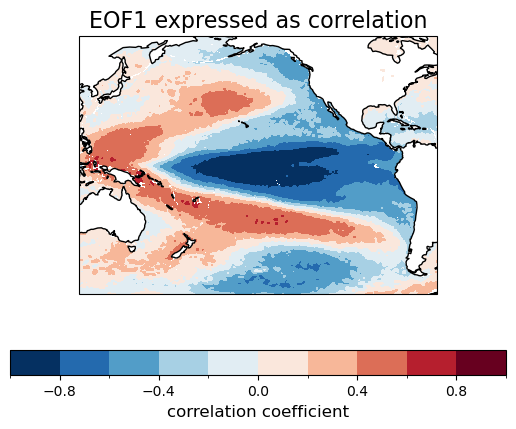

/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


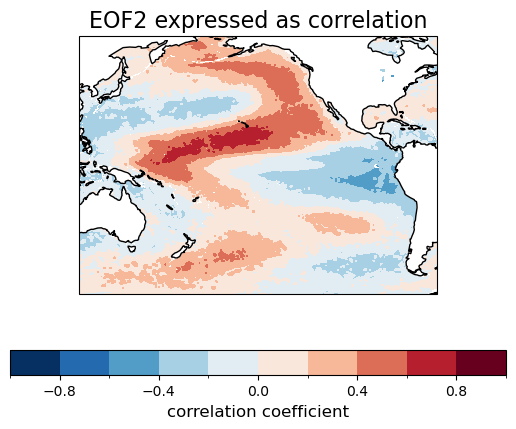

/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


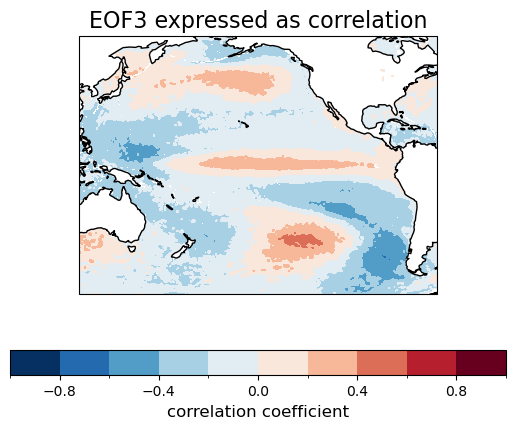

/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


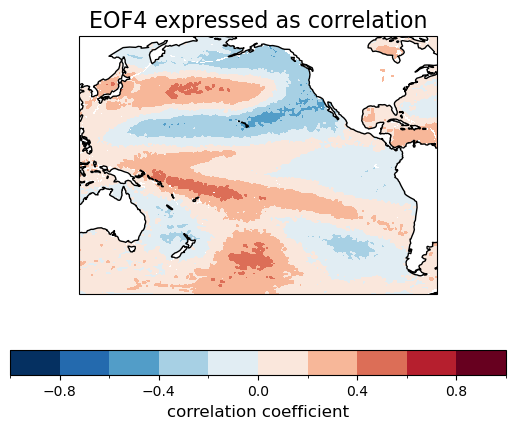

/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


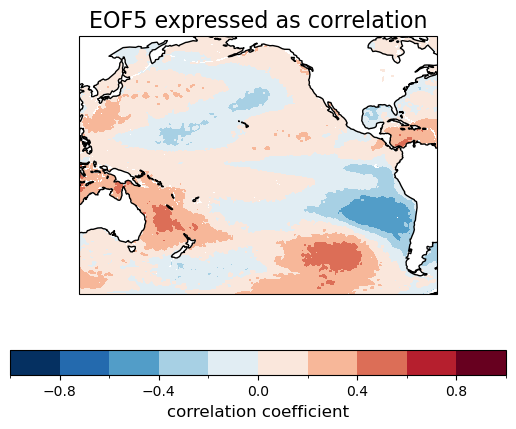

In [17]:
clevs = np.linspace(-1, 1, 11)
for n in range(0,5):
    ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=190))
    fill = eofs_5[n].plot.contourf(ax=ax, levels=clevs, cmap=plt.cm.RdBu_r,
                                add_colorbar=False, transform=ccrs.PlateCarree())
    ax.add_feature(cfeature.COASTLINE, color='k', edgecolor='k')
    cb = plt.colorbar(fill, orientation='horizontal')
    cb.set_label('correlation coefficient', fontsize=12)
    ax.set_title('EOF'+str(n+1)+' expressed as correlation', fontsize=16)
    plt.show()

# 4) Plot of percent variance explained by first 10 EOFs

In [18]:
varfrac = solver.varianceFraction()

(2.6149865421914303e-14, 19.767906188964844)

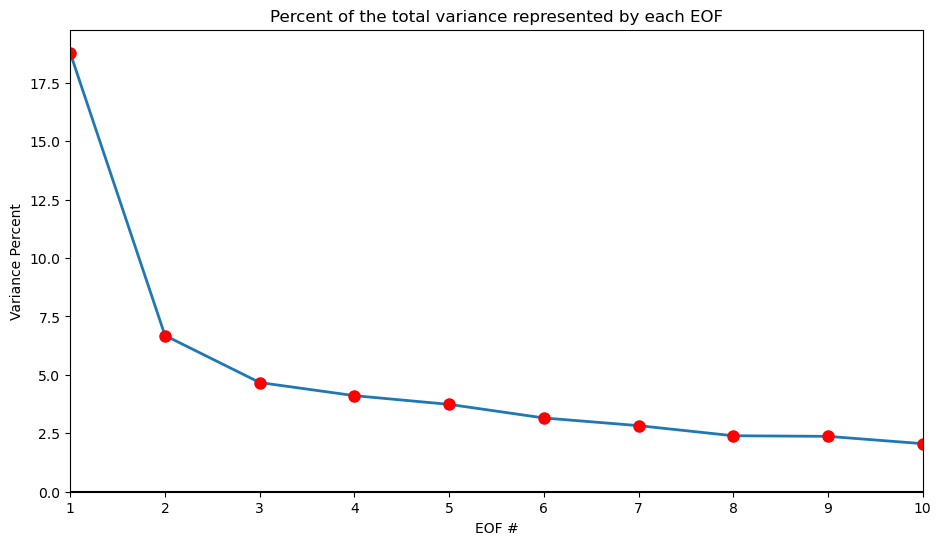

In [19]:
# Plot the fraction of variance explained by each EOF
plt.figure(figsize=(11,6))
eof_num = range(1, 11)
plt.plot(eof_num, varfrac[0:10]*100, linewidth=2)
plt.plot(eof_num, varfrac[0:10]*100, linestyle='None', marker="o", color='r', markersize=8)
plt.axhline(0, color='k')
plt.xticks(range(1, 16))
plt.title('Percent of the total variance represented by each EOF')
plt.xlabel('EOF #')
plt.ylabel('Variance Percent')
plt.xlim(1, 10)
plt.ylim(np.min(varfrac)*100, np.max(varfrac)*100+1)

# 5) 
- Reconstruct SST field using first 5 EOFs 
- Plot a map of Pearson's correlation coefficient (xarray.corr) of:

    a) reconstructed monthly times series 

    b) observed sst time series

In [20]:
reconstruction = solver.reconstructedField(5)
reconstruction

<xarray.DataArray (time: 552, latitude: 521, longitude: 721)> Size: 829MB
array([[[        nan,         nan,         nan, ...,  0.23443532,
          0.2432501 ,  0.24927859],
        [        nan,         nan,         nan, ...,  0.25388175,
          0.25440982,  0.2536779 ],
        [        nan,         nan,         nan, ...,  0.26104248,
          0.26391113,  0.2641526 ],
        ...,
        [ 0.03192525,  0.02757162,  0.02315763, ...,         nan,
                 nan,         nan],
        [ 0.02217934,  0.01957125,  0.01695889, ...,         nan,
                 nan,         nan],
        [ 0.01803428,  0.01666642,  0.01651949, ...,         nan,
                 nan,         nan]],

       [[        nan,         nan,         nan, ...,  0.45093587,
          0.4560998 ,  0.45621786],
        [        nan,         nan,         nan, ...,  0.45677775,
          0.44880104,  0.43971792],
        [        nan,         nan,         nan, ...,  0.44968793,
          0.44975665,  0.44530737],
...
        [ 0.05956942,  0.05893925,  0.05831029, ...,         nan,
                 nan,         nan],
        [ 0.02451937,  0.02321665,  0.02178981, ...,         nan,
                 nan,         nan],
        [-0.00524222, -0.00512901, -0.00370126, ...,         nan,
                 nan,         nan]],

       [[        nan,         nan,         nan, ...,  0.14515595,
          0.16461852,  0.18178818],
        [        nan,         nan,         nan, ...,  0.15693988,
          0.17386521,  0.19083722],
        [        nan,         nan,         nan, ...,  0.1852575 ,
          0.20772663,  0.227931  ],
        ...,
        [ 0.02585762,  0.03281377,  0.03960552, ...,         nan,
                 nan,         nan],
        [-0.02786994, -0.02659451, -0.02519453, ...,         nan,
                 nan,         nan],
        [-0.0839633 , -0.08327596, -0.08276728, ...,         nan,
                 nan,         nan]]], shape=(552, 521, 721), dtype=float32)
Coordinates:
  * time       (time) datetime64[ns] 4kB 1979-01-01 1979-02-01 ... 2024-12-01
  * latitude   (latitude) float64 4kB 65.0 64.75 64.5 ... -64.5 -64.75 -65.0
  * longitude  (longitude) float64 6kB -240.0 -239.8 -239.5 ... -60.25 -60.0
Attributes:
    long_name:  None_reconstructed_with_5_EOFs

/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


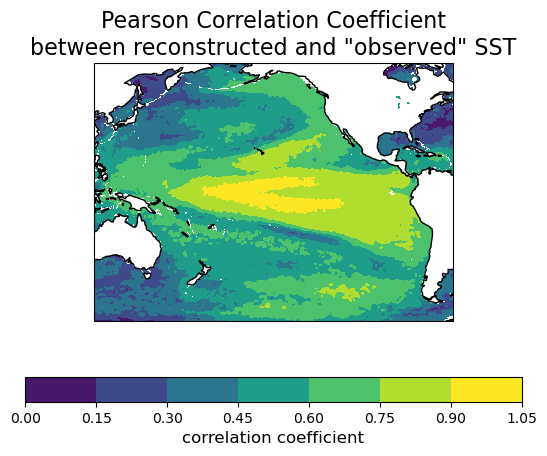

In [21]:
cc = xr.corr(reconstruction, anom_scaled_da, dim='time')

ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=190))
fill = cc.plot.contourf(ax=ax, add_colorbar=False, transform=ccrs.PlateCarree())
ax.add_feature(cfeature.COASTLINE, color='k', edgecolor='k')
cb = plt.colorbar(fill, orientation='horizontal')
cb.set_label('correlation coefficient', fontsize=12)
ax.set_title('Pearson Correlation Coefficient\nbetween reconstructed and "observed" SST', fontsize=16)
plt.show()

In [22]:
ds = ds.rename({'valid_time':'time'})
ds

<xarray.Dataset> Size: 3GB
Dimensions:    (time: 552, latitude: 521, longitude: 721)
Coordinates:
    number     int64 8B ...
  * time       (time) datetime64[ns] 4kB 1979-01-01 1979-02-01 ... 2024-12-01
  * latitude   (latitude) float64 4kB 65.0 64.75 64.5 ... -64.5 -64.75 -65.0
  * longitude  (longitude) float64 6kB -240.0 -239.8 -239.5 ... -60.25 -60.0
    expver     (time) <U4 9kB dask.array<chunksize=(552,), meta=np.ndarray>
Data variables:
    sst        (time, latitude, longitude) float32 829MB dask.array<chunksize=(552, 521, 721), meta=np.ndarray>
    lsm        (time, latitude, longitude) float32 829MB dask.array<chunksize=(552, 521, 721), meta=np.ndarray>
    tcwv       (time, latitude, longitude) float32 829MB dask.array<chunksize=(552, 521, 721), meta=np.ndarray>
    mask_sst   (time, latitude, longitude) float32 829MB dask.array<chunksize=(552, 521, 721), meta=np.ndarray>
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-10-13T19:42 GRIB to CDM+CF via cfgrib-0.9.1...

In [23]:
cc_obs = xr.corr(reconstruction, ds['mask_sst'], dim='time')

/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


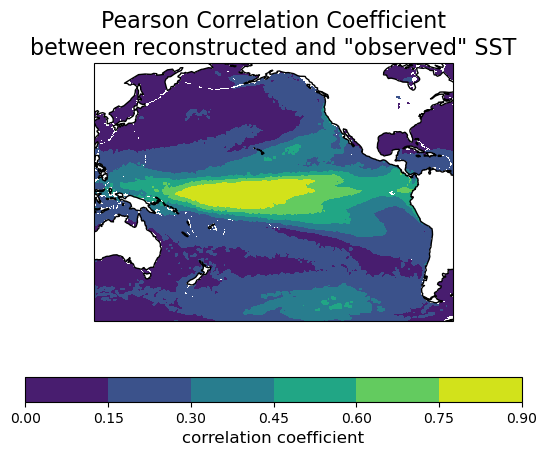

In [24]:
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=190))
fill = cc_obs.plot.contourf(ax=ax, add_colorbar=False, transform=ccrs.PlateCarree())
ax.add_feature(cfeature.COASTLINE, color='k', edgecolor='k')
cb = plt.colorbar(fill, orientation='horizontal')
cb.set_label('correlation coefficient', fontsize=12)
ax.set_title('Pearson Correlation Coefficient\nbetween reconstructed and "observed" SST', fontsize=16)
plt.show()

# 6) Compute a map of Pearson's CC between SST EOF 1 and...
- monthly mean detrended: detr['tcwv]
- desearsonalized: anom['tcwv']
- standardized monthly mean column water vapor anomolies: anom_scaled_wv

... don't mask over land!

See anything interesting?

Compute EOFs by sst but use that EOF to compare with anomolies of another variable... what is relationhip between SST anomolies and water column anomolies
- go through same process to compute SST anomolies but for water vapor
- Reconstructed SST anomolies (X) and water vapor anomolies (Y)
- calculate CC at each point and plot it on a map

EOFs allow us to discriminate between different physical forcings

In [25]:
detr = detr.rename({'valid_time':'time'})
detr

<xarray.Dataset> Size: 2GB
Dimensions:    (time: 552, latitude: 521, longitude: 721)
Coordinates:
    number     int64 8B 0
  * time       (time) datetime64[ns] 4kB 1979-01-01 1979-02-01 ... 2024-12-01
  * latitude   (latitude) float64 4kB 65.0 64.75 64.5 ... -64.5 -64.75 -65.0
  * longitude  (longitude) float64 6kB -240.0 -239.8 -239.5 ... -60.25 -60.0
    expver     (time) <U4 9kB '0001' '0001' '0001' ... '0001' '0001' '0001'
Data variables:
    mask_sst   (time, latitude, longitude) float32 829MB dask.array<chunksize=(552, 521, 721), meta=np.ndarray>
    tcwv       (time, latitude, longitude) float32 829MB dask.array<chunksize=(552, 521, 721), meta=np.ndarray>

In [26]:
anom = anom.rename({'valid_time':'time'})
anom

<xarray.Dataset> Size: 2GB
Dimensions:    (time: 552, latitude: 521, longitude: 721)
Coordinates:
    number     (time) int64 4kB 0 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0 0
  * time       (time) datetime64[ns] 4kB 1979-01-01 1979-02-01 ... 2024-12-01
  * latitude   (latitude) float64 4kB 65.0 64.75 64.5 ... -64.5 -64.75 -65.0
  * longitude  (longitude) float64 6kB -240.0 -239.8 -239.5 ... -60.25 -60.0
    expver     (time) <U4 9kB '0001' '0001' '0001' ... '0001' '0001' '0001'
    month      (time) int64 4kB 1 2 3 4 5 6 7 8 9 10 ... 3 4 5 6 7 8 9 10 11 12
Data variables:
    mask_sst   (time, latitude, longitude) float32 829MB dask.array<chunksize=(1, 521, 721), meta=np.ndarray>
    tcwv       (time, latitude, longitude) float32 829MB dask.array<chunksize=(1, 521, 721), meta=np.ndarray>

In [27]:
anom_rs_wv = anom['tcwv'].values.reshape(anom.time.shape[0], -1)
scaler_anom_wv = preprocessing.StandardScaler().fit(anom_rs_wv)

anom_rs_scaled_wv = scaler_anom.transform(anom_rs_wv)
print(anom_rs_scaled_wv.shape)

anom_scaled_wv = anom_rs_scaled_wv.reshape(anom['tcwv'].shape)
anom_scaled_wv

(552, 375641)


array([[[        nan,         nan,         nan, ...,  3.0141008 ,
          3.0245092 ,  2.9999928 ],
        [        nan,         nan,         nan, ...,  2.8340187 ,
          2.8540897 ,  2.857845  ],
        [        nan,         nan,         nan, ...,  2.8066783 ,
          2.8432958 ,  2.8518252 ],
        ...,
        [-4.8474445 , -4.8532047 , -4.8423715 , ...,         nan,
                 nan,         nan],
        [-4.778582  , -4.7969813 , -4.793545  , ...,         nan,
                 nan,         nan],
        [-4.4201307 , -4.43755   , -4.421494  , ...,         nan,
                 nan,         nan]],

       [[        nan,         nan,         nan, ...,  2.265693  ,
          2.3082235 ,  2.324968  ],
        [        nan,         nan,         nan, ...,  2.2002735 ,
          2.2452269 ,  2.2785878 ],
        [        nan,         nan,         nan, ...,  2.2497396 ,
          2.315701  ,  2.3568835 ],
        ...,
        [-0.7037251 , -0.6479414 , -0.59185725, ...,  

In [28]:
dims = ('time', 'latitude', 'longitude')
time = ds.time.values
latitude = ds.latitude.values
longitude = ds.longitude.values
coords = {'time': time, 'latitude': latitude, 'longitude':longitude}
anom_scaled_da_wv = xr.DataArray(anom_scaled_wv, coords=coords, dims=dims)
anom_scaled_da_wv

<xarray.DataArray (time: 552, latitude: 521, longitude: 721)> Size: 829MB
array([[[        nan,         nan,         nan, ...,  3.0141008 ,
          3.0245092 ,  2.9999928 ],
        [        nan,         nan,         nan, ...,  2.8340187 ,
          2.8540897 ,  2.857845  ],
        [        nan,         nan,         nan, ...,  2.8066783 ,
          2.8432958 ,  2.8518252 ],
        ...,
        [-4.8474445 , -4.8532047 , -4.8423715 , ...,         nan,
                 nan,         nan],
        [-4.778582  , -4.7969813 , -4.793545  , ...,         nan,
                 nan,         nan],
        [-4.4201307 , -4.43755   , -4.421494  , ...,         nan,
                 nan,         nan]],

       [[        nan,         nan,         nan, ...,  2.265693  ,
          2.3082235 ,  2.324968  ],
        [        nan,         nan,         nan, ...,  2.2002735 ,
          2.2452269 ,  2.2785878 ],
        [        nan,         nan,         nan, ...,  2.2497396 ,
          2.315701  ,  2.3568835 ],
...
        [ 1.6231257 ,  1.639696  ,  1.6474338 , ...,         nan,
                 nan,         nan],
        [ 1.8176847 ,  1.8222222 ,  1.8222936 , ...,         nan,
                 nan,         nan],
        [ 1.8357198 ,  1.8342211 ,  1.8133097 , ...,         nan,
                 nan,         nan]],

       [[        nan,         nan,         nan, ..., -1.7197858 ,
         -1.7202195 , -1.697783  ],
        [        nan,         nan,         nan, ..., -1.5936543 ,
         -1.6016023 , -1.6004322 ],
        [        nan,         nan,         nan, ..., -1.5489429 ,
         -1.5641546 , -1.5636392 ],
        ...,
        [ 4.7589273 ,  4.6698017 ,  4.563091  , ...,         nan,
                 nan,         nan],
        [ 4.8534384 ,  4.7884793 ,  4.695449  , ...,         nan,
                 nan,         nan],
        [ 4.6486864 ,  4.6013403 ,  4.525377  , ...,         nan,
                 nan,         nan]]], shape=(552, 521, 721), dtype=float32)
Coordinates:
  * time       (time) datetime64[ns] 4kB 1979-01-01 1979-02-01 ... 2024-12-01
  * latitude   (latitude) float64 4kB 65.0 64.75 64.5 ... -64.5 -64.75 -65.0
  * longitude  (longitude) float64 6kB -240.0 -239.8 -239.5 ... -60.25 -60.0

/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


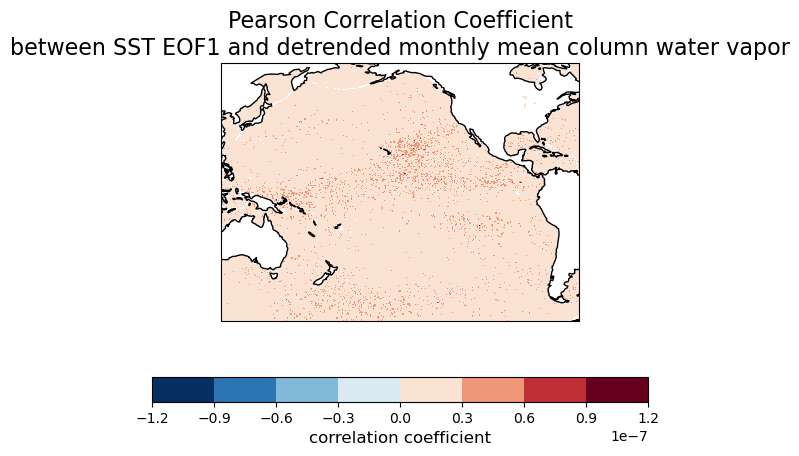

/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


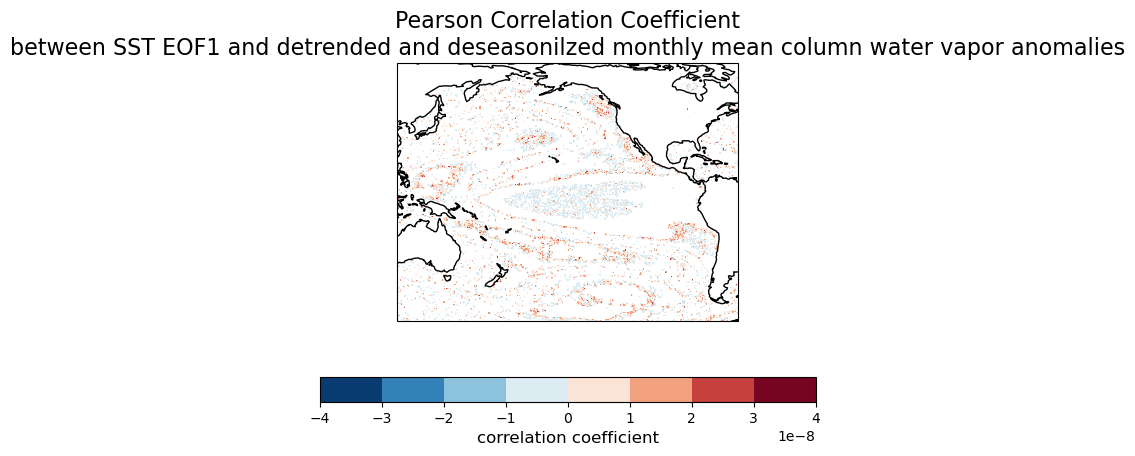

/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


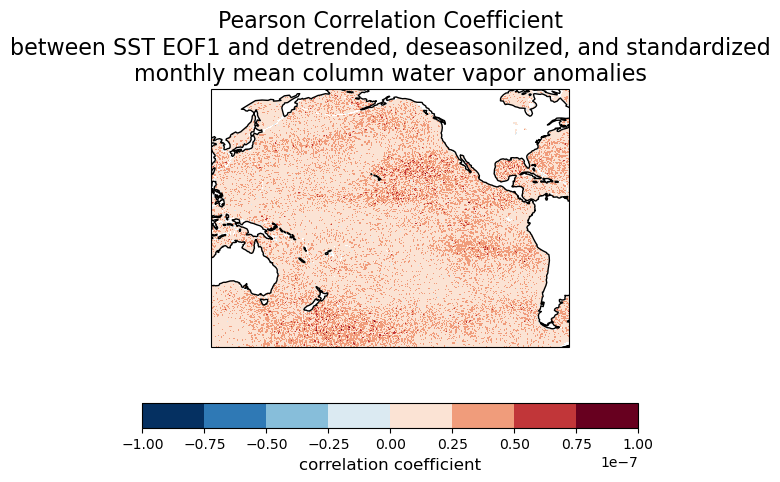

In [29]:
cc_eof1_detrwv = xr.corr(eofs_5[0], detr['tcwv'], dim='time')

ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=190))
fill = cc_eof1_detrwv.plot.contourf(ax=ax, add_colorbar=False, transform=ccrs.PlateCarree())
ax.add_feature(cfeature.COASTLINE, color='k', edgecolor='k')
cb = plt.colorbar(fill, orientation='horizontal')
cb.set_label('correlation coefficient', fontsize=12)
ax.set_title('Pearson Correlation Coefficient\nbetween SST EOF1 and detrended monthly mean column water vapor', fontsize=16)
plt.show()

cc_eof1_anomwv = xr.corr(eofs_5[0], anom['tcwv'], dim='time')

ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=190))
fill = cc_eof1_anomwv.plot.contourf(ax=ax, add_colorbar=False, transform=ccrs.PlateCarree())
ax.add_feature(cfeature.COASTLINE, color='k', edgecolor='k')
cb = plt.colorbar(fill, orientation='horizontal')
cb.set_label('correlation coefficient', fontsize=12)
ax.set_title('Pearson Correlation Coefficient\nbetween SST EOF1 and detrended and deseasonilzed monthly mean column water vapor anomalies', fontsize=16)
plt.show()

cc_eof1_wv = xr.corr(eofs_5[0], anom_scaled_da_wv, dim='time')

ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=190))
fill = cc_eof1_wv.plot.contourf(ax=ax, add_colorbar=False, transform=ccrs.PlateCarree())
ax.add_feature(cfeature.COASTLINE, color='k', edgecolor='k')
cb = plt.colorbar(fill, orientation='horizontal')
cb.set_label('correlation coefficient', fontsize=12)
ax.set_title('Pearson Correlation Coefficient\nbetween SST EOF1 and detrended, deseasonilzed, and standardized\nmonthly mean column water vapor anomalies', fontsize=16)
plt.show()